# Mini Project: Simulasi Navigasi Robot Berbasis Grid

Nama : Aprian Syahrani

NIM: 11251023

Kelas : A

Mata Kuliah : Pengantar Kecerdasan Artifisial | IF2514302

Dosen Pengampu: Bima Prihasto, S.Si., M.Si., Ph.D.


## Perbandingan Greedy Best-First Search dan A*
**metrik yang digunakan:**
- **Path Length:** jumlah perpindahan (`jumlah koordinat path - 1`). Jika tidak ada jalur, nilainya “Tidak tersedia”.
- **Nodes Explored:** jumlah node valid yang dikeluarkan dari priority queue dan diproses, termasuk goal jika ditemukan.
- **Execution Time:** median waktu fungsi pencarian dari 100 pengulangan, dalam milidetik. Visualisasi dan pencetakan tidak dihitung.
- **Success Status:** berhasil jika jalur ditemukan, gagal jika tidak ada jalur.


## 1. Import Library dan Definisi Skenario

In [3]:
# Jalankan sel ini terlebih dahulu.
import heapq
import itertools
import time
import statistics
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display



In [4]:
# ============================================================
# 1. DEFINISI SKENARIO GRID
# Simbol: S = start, G = goal, # = obstacle, . = sel bebas
# Semua peta berukuran 10 x 10.
# ============================================================
SCENARIOS = {
    1: {
        "name": "Grid relatif terbuka",
        "description": "Grid dasar dengan beberapa rintangan tersebar.",
        "rows": [
            "S.........",
            "..#.......",
            "......#...",
            "...#......",
            ".........#",
            ".#........",
            "......#...",
            "....#.....",
            ".........#",
            ".........G",
        ],
    },
    2: {
        "name": "Rintangan yang memaksa jalan memutar",
        "description": "Dinding vertikal dan blok rintangan memaksa robot mencari jalur alternatif.",
        "rows": [
            "S....#....",
            ".....##..#",
            "#......##.",
            ".........#",
            ".....#..#.",
            ".........#",
            "....#.##..",
            ".......#..",
            "..##...##.",
            ".#.#..##.G",
        ],
    },
    3: {
        "name": "Koridor sempit berkelok",
        "description": "Lorong satu sel membentuk jalur berkelok dari start ke goal.",
        "rows": [
            "S.........",
            "#########.",
            "..........",
            ".#########",
            "..........",
            "#########.",
            "..........",
            ".#########",
            "..........",
            ".........G",
        ],
    },
    4: {
        "name": "Goal tidak dapat dijangkau",
        "description": "Satu baris rintangan penuh memisahkan start dan goal.",
        "rows": [
            "S.........",
            "..........",
            "##########",
            "..........",
            "..........",
            "..........",
            "..........",
            "..........",
            "..........",
            ".........G",
        ],
    },
}


def parse_grid(rows):
    """Konversi list string menjadi grid dan koordinat start/goal."""
    grid = [list(row) for row in rows]
    if not grid or any(len(row) != len(grid[0]) for row in grid):
        raise ValueError("Grid harus berbentuk persegi panjang.")
    starts, goals = [], []
    for r, row in enumerate(grid):
        for c, value in enumerate(row):
            if value == "S":
                starts.append((r, c))
            elif value == "G":
                goals.append((r, c))
            elif value not in (".", "#"):
                raise ValueError(f"Simbol grid tidak dikenal: {value}")
    if len(starts) != 1 or len(goals) != 1:
        raise ValueError("Setiap grid harus memiliki tepat satu S dan satu G.")
    return grid, starts[0], goals[0]


def manhattan(a, b):
    """Heuristik Manhattan untuk gerakan atas, bawah, kiri, dan kanan."""
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


# Urutan tetangga dibuat tetap agar hasil tie-breaking konsisten.
DIRECTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]


def neighbors(grid, node):
    rows, cols = len(grid), len(grid[0])
    r, c = node
    for dr, dc in DIRECTIONS:
        nr, nc = r + dr, c + dc
        if 0 <= nr < rows and 0 <= nc < cols and grid[nr][nc] != "#":
            yield (nr, nc)


def reconstruct_path(parent, goal):
    if goal not in parent:
        return []
    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = parent[current]
    path.reverse()
    return path


def greedy_best_first(grid, start, goal):
    """Mengembalikan (path, explored_order); prioritas utama adalah h(n)."""
    counter = itertools.count()
    frontier = [(manhattan(start, goal), next(counter), start)]
    parent = {start: None}
    discovered = {start}
    explored_order = []

    while frontier:
        _, _, current = heapq.heappop(frontier)
        explored_order.append(current)  # Goal turut dihitung jika berhasil ditemukan.
        if current == goal:
            return reconstruct_path(parent, goal), explored_order

        for nxt in neighbors(grid, current):
            if nxt not in discovered:
                discovered.add(nxt)
                parent[nxt] = current
                heapq.heappush(
                    frontier,
                    (manhattan(nxt, goal), next(counter), nxt),
                )

    return [], explored_order


def a_star(grid, start, goal):
    """Mengembalikan (path, explored_order); prioritas utama adalah g(n) + h(n)."""
    counter = itertools.count()
    start_h = manhattan(start, goal)
    # Tuple: (f_score, h_score, insertion_order, g_snapshot, node)
    frontier = [(start_h, start_h, next(counter), 0, start)]
    parent = {start: None}
    g_score = {start: 0}
    closed = set()
    explored_order = []

    while frontier:
        _, _, _, g_snapshot, current = heapq.heappop(frontier)

        # Abaikan entri lama ketika node sudah mendapat g-score yang lebih baik.
        if g_snapshot != g_score.get(current):
            continue
        if current in closed:
            continue

        closed.add(current)
        explored_order.append(current)  # Goal turut dihitung jika berhasil ditemukan.
        if current == goal:
            return reconstruct_path(parent, goal), explored_order

        for nxt in neighbors(grid, current):
            tentative_g = g_score[current] + 1
            if tentative_g < g_score.get(nxt, float("inf")):
                g_score[nxt] = tentative_g
                parent[nxt] = current
                h_score = manhattan(nxt, goal)
                f_score = tentative_g + h_score
                heapq.heappush(
                    frontier,
                    (f_score, h_score, next(counter), tentative_g, nxt),
                )

    return [], explored_order


ALGORITHMS = {
    "Greedy Best-First Search": greedy_best_first,
    "A* Search": a_star,
}


def run_one(grid, start, goal, search_function, repeats=100):
    """Jalankan pencarian dan hitung median waktu hanya untuk fungsi pencarian."""
    durations_ms = []
    final_path, final_explored = [], []
    for _ in range(repeats):
        t0 = time.perf_counter()
        path, explored = search_function(grid, start, goal)
        durations_ms.append((time.perf_counter() - t0) * 1000)
        final_path, final_explored = path, explored
    return {
        "path": final_path,
        "explored": final_explored,
        "path_length": len(final_path) - 1 if final_path else None,
        "nodes_explored": len(final_explored),
        "median_time_ms": statistics.median(durations_ms),
        "success": bool(final_path),
    }




## 2. Jalankan Eksperimen dan Buat Tabel Hasil


In [5]:
# ============================================================
# 2. VALIDASI PETA DAN JALANKAN EKSPERIMEN
# ============================================================
results = []
run_details = {}

for scenario_id, scenario in SCENARIOS.items():
    grid, start, goal = parse_grid(scenario["rows"])
    for algo_name, search_function in ALGORITHMS.items():
        result = run_one(grid, start, goal, search_function, repeats=100)
        run_details[(scenario_id, algo_name)] = {
            **result,
            "grid": grid,
            "start": start,
            "goal": goal,
        }
        results.append({
            "Skenario": scenario_id,
            "Kondisi": scenario["name"],
            "Algoritma": algo_name,
            "Path Length": result["path_length"] if result["path_length"] is not None else "Tidak tersedia",
            "Nodes Explored": result["nodes_explored"],
            "Median Execution Time (ms)": round(result["median_time_ms"], 5),
            "Success Status": "Berhasil" if result["success"] else "Gagal - tidak ada jalur",
        })

results_df = pd.DataFrame(results)
print("RINGKASAN HASIL EKSPERIMEN")
display(results_df)

# Simpan tabel ringkasan agar mudah diunduh dari panel Files Google Colab.
results_df.to_csv("hasil_eksperimen_navigasi_robot.csv", index=False)
print("File tersimpan: hasil_eksperimen_navigasi_robot.csv")




RINGKASAN HASIL EKSPERIMEN


,Skenario,Kondisi,Algoritma,Path Length,Nodes Explored,Median Execution Time (ms),Success Status
0,1,Grid relatif terbuka,Greedy Best-First Search,18,19,0.02729,Berhasil
1,1,Grid relatif terbuka,A* Search,18,19,0.06621,Berhasil
2,2,Rintangan yang memaksa jalan memutar,Greedy Best-First Search,22,30,0.04269,Berhasil
3,2,Rintangan yang memaksa jalan memutar,A* Search,18,35,0.07063,Berhasil
4,3,Koridor sempit berkelok,Greedy Best-First Search,54,55,0.05828,Berhasil
5,3,Koridor sempit berkelok,A* Search,54,55,0.07894,Berhasil
6,4,Goal tidak dapat dijangkau,Greedy Best-First Search,Tidak tersedia,20,0.02204,Gagal - tidak ada jalur
7,4,Goal tidak dapat dijangkau,A* Search,Tidak tersedia,20,0.03632,Gagal - tidak ada jalur


File tersimpan: hasil_eksperimen_navigasi_robot.csv


## 3. Jalur dan Node yang Dieksplorasi


In [6]:
# ============================================================
# 3. TAMPILKAN JALUR DAN URUTAN NODE YANG DIEKSPLORASI
# ============================================================
for scenario_id, scenario in SCENARIOS.items():
    print(f"\nSKENARIO {scenario_id}: {scenario['name']}")
    for algo_name in ALGORITHMS:
        result = run_details[(scenario_id, algo_name)]
        print(f"  {algo_name}")
        print(f"    Status       : {'Berhasil' if result['success'] else 'Gagal - tidak ada jalur'}")
        print(f"    Path Length  : {result['path_length'] if result['path_length'] is not None else 'Tidak tersedia'}")
        print(f"    Nodes Explored: {result['nodes_explored']}")
        print(f"    Path         : {result['path'] if result['path'] else 'Tidak ditemukan'}")
        print(f"    Explored     : {result['explored']}")





SKENARIO 1: Grid relatif terbuka
  Greedy Best-First Search
    Status       : Berhasil
    Path Length  : 18
    Nodes Explored: 19
    Path         : [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]
    Explored     : [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]
  A* Search
    Status       : Berhasil
    Path Length  : 18
    Nodes Explored: 19
    Path         : [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]
    Explored     : [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]

SKENARIO 2: Rintangan yang memaksa jalan memutar
  Greedy Best-First Search
    Status      

## 4. Visualisasi Hasil
Setiap skenario ditampilkan dalam dua panel agar jalur Greedy dan A* dapat dibandingkan pada peta yang sama.

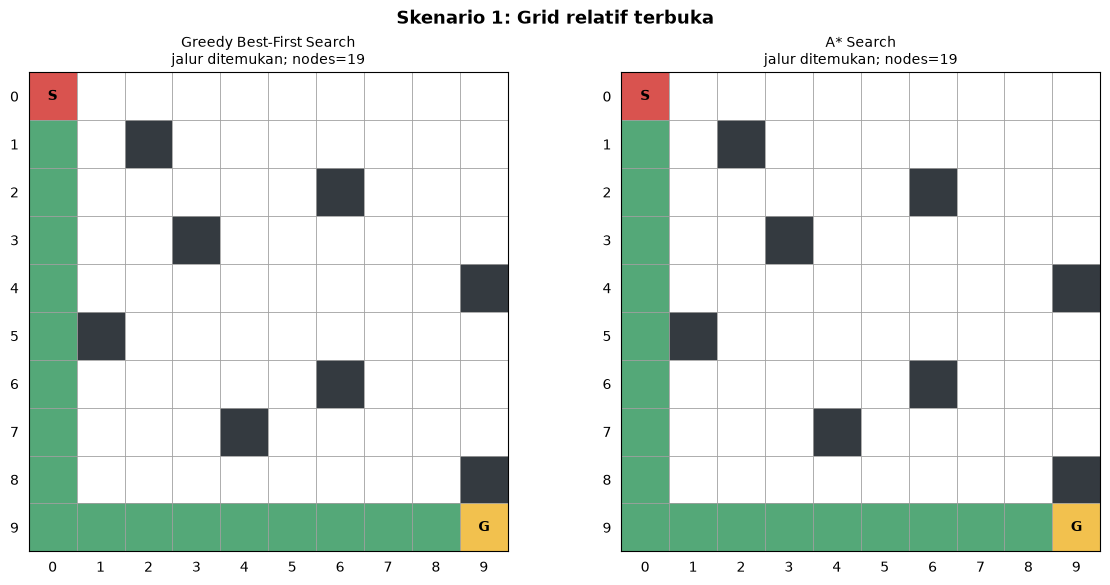

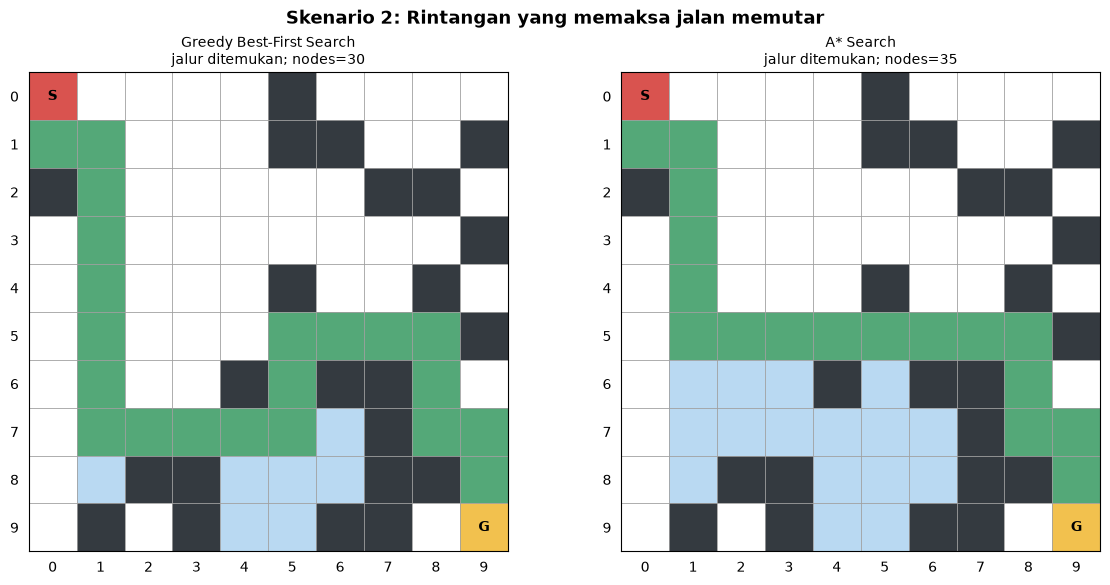

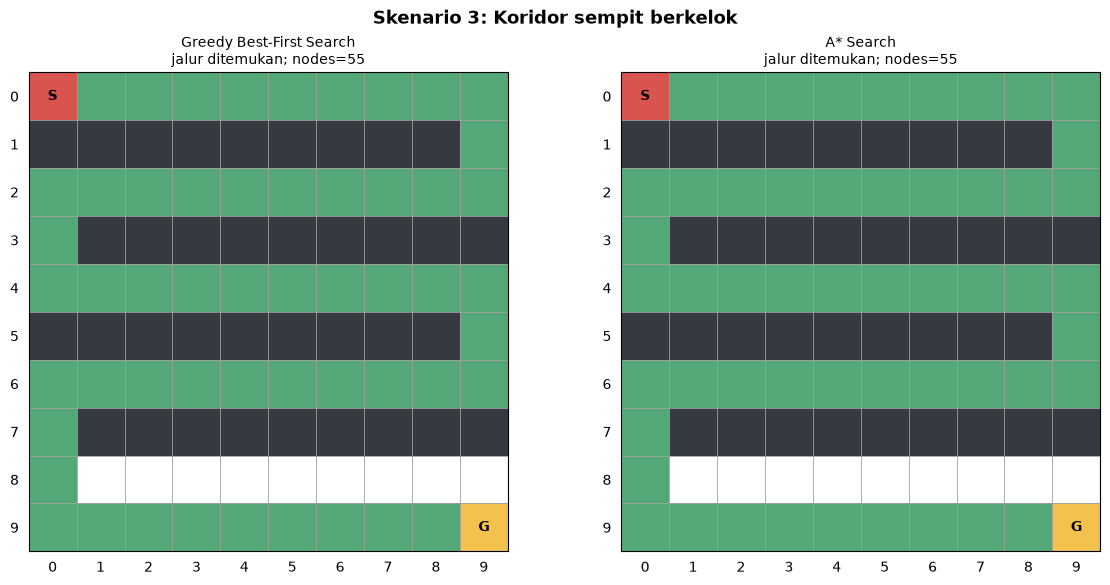

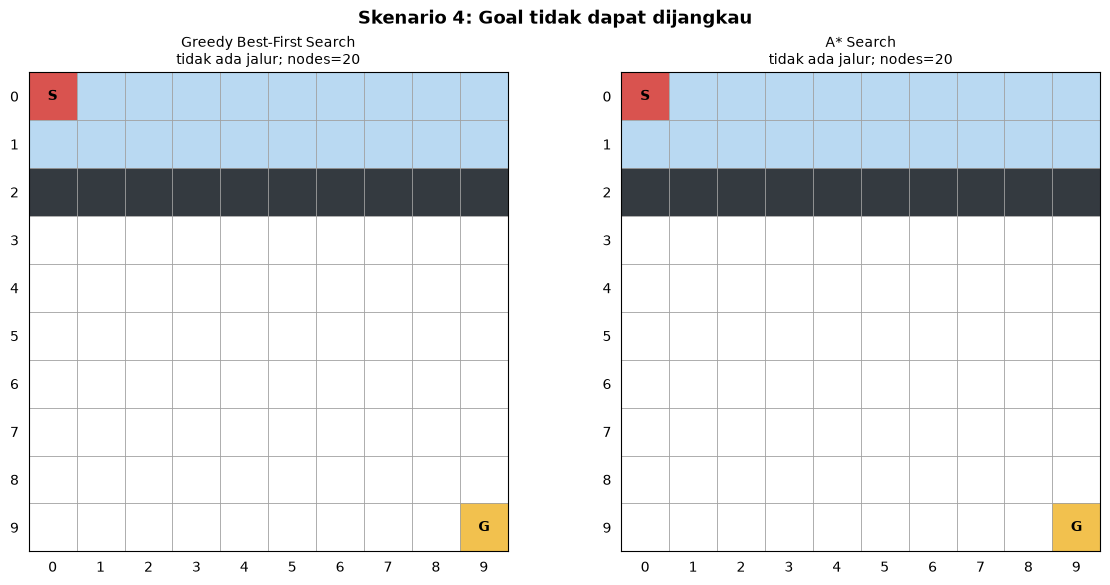

In [7]:
# ============================================================
# 4. VISUALISASI GRID, NODE YANG DIEKSPLORASI, DAN PATH
# ============================================================
def draw_result(ax, grid, result, start, goal, title):
    rows, cols = len(grid), len(grid[0])
    # 0 = sel bebas, 1 = rintangan, 2 = dieksplorasi, 3 = path
    matrix = [[1 if grid[r][c] == "#" else 0 for c in range(cols)] for r in range(rows)]
    for r, c in result["explored"]:
        if grid[r][c] != "#":
            matrix[r][c] = 2
    for r, c in result["path"]:
        if grid[r][c] != "#":
            matrix[r][c] = 3
    matrix[start[0]][start[1]] = 4
    matrix[goal[0]][goal[1]] = 5

    cmap = ListedColormap(["white", "#343A40", "#B9D9F2", "#54A878", "#D9534F", "#F2C14E"])
    ax.imshow(matrix, cmap=cmap, vmin=0, vmax=5)
    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_xticks([x - 0.5 for x in range(1, cols)], minor=True)
    ax.set_yticks([y - 0.5 for y in range(1, rows)], minor=True)
    ax.grid(which="minor", color="#A0A0A0", linestyle="-", linewidth=0.6)
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=True, labelleft=True)
    ax.text(start[1], start[0], "S", ha="center", va="center", weight="bold", color="black")
    ax.text(goal[1], goal[0], "G", ha="center", va="center", weight="bold", color="black")
    status = "jalur ditemukan" if result["success"] else "tidak ada jalur"
    ax.set_title(f"{title}\n{status}; nodes={result['nodes_explored']}", fontsize=10)
    ax.set_xlim(-0.5, cols - 0.5)
    ax.set_ylim(rows - 0.5, -0.5)


for scenario_id, scenario in SCENARIOS.items():
    grid, start, goal = parse_grid(scenario["rows"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.8))
    fig.suptitle(f"Skenario {scenario_id}: {scenario['name']}", fontsize=13, fontweight="bold")
    draw_result(axes[0], grid, run_details[(scenario_id, "Greedy Best-First Search")], start, goal,
                "Greedy Best-First Search")
    draw_result(axes[1], grid, run_details[(scenario_id, "A* Search")], start, goal, "A* Search")
    fig.tight_layout()
    plt.show()


